# 5. Model CNN-LSTM

Rovnaké príznaky ResNet18 ako pri CNN-SVM, ale namiesto priemeru ich číta
**LSTM** (rekurentná sieť) **postupne, snímka po snímke**. LSTM si udržiava skrytý stav –
pamäť toho, čo videla doteraz – a môže tak zachytiť priebeh pohybu.
Po 16. snímke skrytý stav opisuje celý klip a lineárna vrstva z neho určí triedu.

Model je realizovaný dvojkrokovo: zmrazená CNN (notebook 2) extrahuje príznaky snímok
a LSTM sa trénuje na nich. Pri zmrazenej CNN je to rovnocenné jednému end-to-end modelu
CNN → LSTM, len rýchlejšie (CNN sa nepočíta v každej epoche znova).

Na rozdiel od SVM sa LSTM trénuje gradientovým zostupom po epochách:
- z trénovacích dát v každom delení oddelíme 20 % zdrojov ako **validačné**,
- po každej epoche meriame validačnú stratu a ponecháme epochu s najnižšou
  (**early stopping**) – sieť sa na malom datasete rýchlo preučí,
- malý model (1 vrstva, 128 neurónov, dropout 0,5) a váhy tried v stratovej funkcii.

Hodnotenie je na rovnakých 10 deleniach ako pri ostatných modeloch.

In [1]:
import copy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GroupShuffleSplit
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from har_utils import CLASSES, make_splits, split_metrics, summarize

df = pd.read_csv("index.csv")
feats = np.load("features_resnet.npy")     # (klipy, 16, 512)
y, ds = df.label.values, df.dataset.values
device = "cuda" if torch.cuda.is_available() else "cpu"

In [2]:
class LSTMClassifier(nn.Module):
    def __init__(self, in_dim=512, hidden=128, n_classes=2, dropout=0.5):
        super().__init__()
        self.lstm = nn.LSTM(in_dim, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, n_classes)

    def forward(self, x):              # x: (batch, 16, 512) – príznaky snímok v poradí
        _, (h, _) = self.lstm(x)       # h: skrytý stav po poslednej snímke
        return self.fc(self.drop(h[-1]))

In [3]:
def train_lstm(X_tr, y_tr, X_va, y_va, seed=0, epochs=40, lr=1e-3, weight_decay=1e-4):
    torch.manual_seed(seed)
    model = LSTMClassifier().to(device)

    counts = np.bincount(y_tr, minlength=2)                    # váhy tried proti nevyváženosti
    w = torch.tensor(counts.sum() / (2 * counts), dtype=torch.float32, device=device)
    criterion = nn.CrossEntropyLoss(weight=w)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loader = DataLoader(TensorDataset(X_tr, torch.tensor(y_tr)), batch_size=32, shuffle=True)
    y_va_t = torch.tensor(y_va, device=device)

    best_loss, best_state, best_epoch, history = np.inf, None, 0, []
    for epoch in range(epochs):
        model.train()
        train_loss = 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * len(yb)

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(X_va.to(device)), y_va_t).item()
        history.append((train_loss / len(y_tr), val_loss))

        if val_loss < best_loss:                               # early stopping
            best_loss, best_state, best_epoch = val_loss, copy.deepcopy(model.state_dict()), epoch + 1

    model.load_state_dict(best_state)
    return model, np.array(history), best_epoch

In [4]:
rows, y_all, p_all, histories = [], [], [], []

for seed, tr, te in make_splits(df):
    # validačná časť z trénovacích dát, tiež podľa zdroja
    inner = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    a, b = next(inner.split(tr, groups=df.source.values[tr]))
    i_tr, i_va = tr[a], tr[b]

    # štandardizácia podľa trénovacích dát
    mu, sd = feats[i_tr].mean(axis=(0, 1)), feats[i_tr].std(axis=(0, 1)) + 1e-6
    to_t = lambda idx: torch.tensor((feats[idx] - mu) / sd, dtype=torch.float32)

    model, hist, best_epoch = train_lstm(to_t(i_tr), y[i_tr], to_t(i_va), y[i_va], seed=seed)
    model.eval()
    with torch.no_grad():
        pred = model(to_t(te).to(device)).argmax(1).cpu().numpy()

    for r in split_metrics(seed, y[te], pred, ds[te]):
        rows.append({**r, "best_epoch": best_epoch})
    y_all.append(y[te])
    p_all.append(pred)
    histories.append((hist, best_epoch))

results = pd.DataFrame(rows)
y_all, p_all = np.concatenate(y_all), np.concatenate(p_all)

Path("results").mkdir(exist_ok=True)
results.to_csv("results/cnn_lstm.csv", index=False)
print(summarize(results, "CNN-LSTM").to_string())

                             acc        bal_acc             f1
model    test_set                                             
CNN-LSTM hmdb      0.858 ± 0.083  0.865 ± 0.074  0.854 ± 0.085


## Priebeh trénovania

Krivky prvého delenia. Ak validačná strata začne rásť, kým trénovacia ďalej klesá,
sieť sa preučuje (zapamätáva si trénovacie klipy). Early stopping preto ponecháva
váhy z epochy s najnižšou validačnou stratou (zvislá čiara).

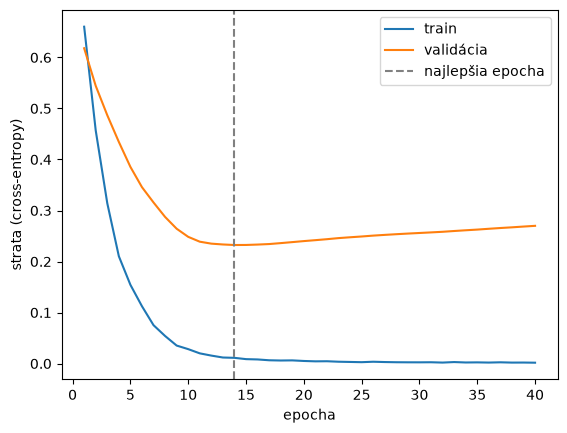

In [5]:
hist, best_epoch = histories[0]
plt.plot(range(1, len(hist) + 1), hist[:, 0], label="train")
plt.plot(range(1, len(hist) + 1), hist[:, 1], label="validácia")
plt.axvline(best_epoch, ls="--", c="gray", label="najlepšia epocha")
plt.xlabel("epocha")
plt.ylabel("strata (cross-entropy)")
plt.legend()
plt.show()

              precision    recall  f1-score   support

         eat       0.77      0.94      0.85       332
        clap       0.94      0.79      0.86       444

    accuracy                           0.85       776
   macro avg       0.86      0.86      0.85       776
weighted avg       0.87      0.85      0.86       776



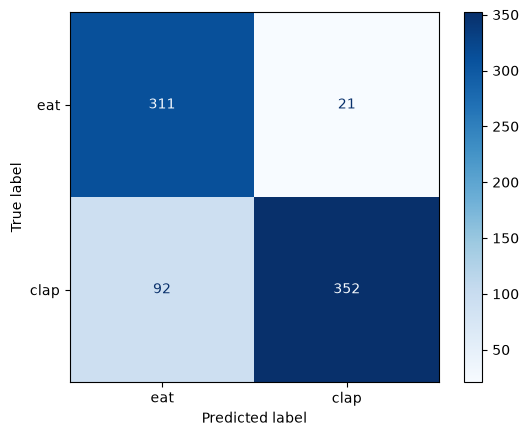

In [6]:
print(classification_report(y_all, p_all, target_names=CLASSES))
ConfusionMatrixDisplay.from_predictions(y_all, p_all, display_labels=CLASSES, cmap="Blues");